# 6 — Trade-off: AST original, Jacobiana, Shao–Wu e Heaps

## Resumo

Comparamos quatro geradores completos, com 5.000 mecanismos independentes e uma trajetória por mecanismo. Mantemos horizontes 96/192/384, explosão operacional acima de 100 ou valor não finito, e cauda de baixa amplitude com 24 valores em [-0.15,0.15]. Medimos proporções, intervalos de Wilson e velocidade por fase. Os resultados são recalculados nesta execução.

Esta execução compara as quatro famílias com inicialização direta do histórico de Shao–Wu. Os resultados e custos são recalculados.

## 1. Desenho

| Método | Família | Inicialização | Inovação |
|---|---|---|---|
| original | AST de somas/produtos | Uniforme [-1,1] | Gaussiana |
| jacobian | AST certificada em caixa | Uniforme no domínio | Uniforme limitada |
| shao-wu | AST com TANH e limites globais | Uniforme [-1,1]; transiente inicial possível | Gaussiana |
| heaps-var | VAR(p) simétrico | Normal estacionária conjunta | Gaussiana |

Todos usam uma variável e inovação com desvio 0.05. Isso mantém a dimensão compatível com o certificado atual da Jacobiana. Os notebooks específicos demonstram duas variáveis. As famílias e distribuições diferem; a comparação mantém número de mecanismos, dimensões, horizontes e variância do ruído.

[Shao–Wu, Teorema 5.1](https://arxiv.org/pdf/math/0611029#page=11); [Heaps, apêndice](https://arxiv.org/pdf/2004.09455#page=11). A amostragem das árvores e o histórico inicial são adaptações do projeto.

In [1]:
from __future__ import annotations
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "src" / "tsfmxai").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tsfmxai.generators import (
    RandomTreeConfig, ContractionTreeConfig, ShaoWuConfig, HeapsVARConfig,
    sample_random_mechanisms, sample_contractive_mechanisms,
    sample_shao_wu_mechanism, sample_shao_wu_mechanisms, sample_shao_wu_trajectories,
    sample_heaps_var_mechanism, sample_heaps_var_mechanisms, sample_heaps_var_trajectories,
    evaluate_expression_with_gradient, evaluate_bound_expression, var_companion_matrix,
    global_expression_bounds,
)
from tsfmxai.evaluation import (
    StabilityDiagnosticConfig, wilson_interval, TailDiagnosticConfig, TAIL_LABELS,
    measure_tail_prefixes, classify_tail_windows,
)
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
BLAS_CONTROLLER = threadpool_limits(limits=1)
ROOT_SEED = 20261001
HORIZONS = (96, 192, 384)
INNOVATION_STD = .05
DIAGNOSTIC_CONFIG = StabilityDiagnosticConfig(HORIZONS, 100., 3 * INNOVATION_STD, 24)
TAIL_CONFIG = TailDiagnosticConfig(window_steps=24, persistence_windows=2,
                                   flat_tolerance=3 * INNOVATION_STD, decline_ratio=.5)
TAIL_TOLERANCES = tuple(factor * INNOVATION_STD for factor in (1., 2., 3.))
BASE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.80,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
SHAO_CONFIG = ShaoWuConfig(tree_config=BASE_CONFIG, innovation_std=INNOVATION_STD,
                           target_gain=.8)
HEAPS_CONFIG = HeapsVARConfig(num_series=1, minimum_order=1, maximum_order=12,
                             unconstrained_std=.45, innovation_std=INNOVATION_STD)

EXPERIMENT_ID = "abstract_syntax_tree_006_four_current_methods_tail_diagnostics_v2"
NOTEBOOK_PATH = "experiments/abstract_syntax_tree/6_stability_methods_tradeoff.ipynb"
RESEARCH_QUESTION = "Qual o trade-off entre falhas operacionais, baixa amplitude e custo dos quatro geradores?"
HYPOTHESIS = "Certificados reduzem falhas nas famílias admitidas, com custo de construção e inicialização."
SAMPLE_COUNT = 5000
METHOD_ORDER = ["original", "jacobian", "shao-wu", "heaps-var"]
CONTRACTION_CONFIG = ContractionTreeConfig(
    tree_config=replace(BASE_CONFIG, coefficient_gate_lags=True),
    domain_radius=1., innovation_bound=np.sqrt(3.)*INNOVATION_STD,
    lag_weight_growth=1.25, target_lipschitz=.90, scale_safety_factor=.95,
)
configuration = {
    "root_seed": ROOT_SEED, "count_per_method": SAMPLE_COUNT, "num_series": 1,
    "diagnostics": asdict(DIAGNOSTIC_CONFIG), "original": asdict(BASE_CONFIG),
    "jacobian": asdict(CONTRACTION_CONFIG), "shao-wu": asdict(SHAO_CONFIG),
    "heaps-var": asdict(HEAPS_CONFIG), "blas_threads": 1, "trajectories_per_mechanism": 1,
    "future_noise": "same Gaussian draws per index for original/Shao-Wu/Heaps; uniform for Jacobian",
    "initialization": {"original": "uniform", "jacobian": "uniform inside D",
                       "shao-wu": "direct uniform [-1,1]; possible initial transient", "heaps-var": "joint invariant Gaussian"},
}
configuration["tail_diagnostics"] = asdict(TAIL_CONFIG)
configuration["tail_sensitivity_tolerances"] = TAIL_TOLERANCES
configuration["tail_criterion"] = "signed per-channel windows; all attempts in primary denominators"
pd.set_option("display.max_columns", None)
print(json.dumps(configuration, indent=2))


{
  "root_seed": 20261001,
  "count_per_method": 5000,
  "num_series": 1,
  "diagnostics": {
    "horizons": [
      96,
      192,
      384
    ],
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24
  },
  "original": {
    "minimum_operators": 1,
    "maximum_operators": 6,
    "num_series": 1,
    "minimum_lag": 1,
    "maximum_lag": 12,
    "parameter_probability": 0.55,
    "time_probability": 0.0,
    "lag_probability": 0.45,
    "add_probability": 0.8,
    "minimum_parameter_magnitude": 0.05,
    "maximum_parameter_magnitude": 0.8,
    "require_lag": true,
    "require_time": false,
    "coefficient_gate_lags": false
  },
  "jacobian": {
    "tree_config": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "min

**O que foi feito.** Fixamos as configurações completas. Cada série tem inovação a cada passo; a inicialização segue a política declarada.

## 2. Amostragem dos mecanismos

In [2]:
samplers = {
    "original": lambda: sample_random_mechanisms(BASE_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "jacobian": lambda: sample_contractive_mechanisms(CONTRACTION_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "shao-wu": lambda: sample_shao_wu_mechanisms(SHAO_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "heaps-var": lambda: sample_heaps_var_mechanisms(HEAPS_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
}
mechanisms_by_method, sampling_times = {}, {}
for method, sampler in samplers.items():
    started = time.perf_counter()
    mechanisms_by_method[method] = sampler()
    sampling_times[method] = time.perf_counter()-started
    assert len(mechanisms_by_method[method]) == SAMPLE_COUNT
    if method != "original":
        assert all(m.certificate.holds for m in mechanisms_by_method[method])
    print(method, "sampling + certification seconds:", round(sampling_times[method], 3), flush=True)
display(pd.DataFrame([
    {"method": method, "index": i, "formula": m.formulas[0] if hasattr(m, "formulas") else m.formula}
    for method, mechanisms in mechanisms_by_method.items() for i, m in enumerate(mechanisms[:2])
]))
additional_checks = {
    "jacobian_certified": sum(m.certificate.holds for m in mechanisms_by_method["jacobian"]),
    "shao_wu_certified": sum(m.certificate.holds for m in mechanisms_by_method["shao-wu"]),
    "heaps_certified": sum(m.certificate.holds for m in mechanisms_by_method["heaps-var"]),
    "shao_wu_max_total_gain": max(m.certificate.total_gain for m in mechanisms_by_method["shao-wu"]),
    "shao_wu_max_drift_bound": max(m.certificate.drift_norm_bound for m in mechanisms_by_method["shao-wu"]),
    "heaps_max_lyapunov_residual": max(m.certificate.relative_lyapunov_residual for m in mechanisms_by_method["heaps-var"]),
}
display(pd.Series(additional_checks))


original sampling + certification seconds: 1.625


jacobian sampling + certification seconds: 3.298


shao-wu sampling + certification seconds: 3.509


heaps-var sampling + certification seconds: 14.409


,method,index,formula
0,original,0,(((-0.727339 + 0.163988) + -0.752925) + x_0(t-7))
1,original,1,(((x_0(t-2) + -0.676288) + -0.610715) + x_0(t-...
2,jacobian,0,x_0(t) = (0.611596 * (((-0.727339 + 0.163988) ...
3,jacobian,1,x_0(t) = (0.141423 * ((((x_0(t-2) * -0.198725)...
4,shao-wu,0,x_0(t) = (0.76 * (((-0.727339 + 0.163988) + -0...
5,shao-wu,1,x_0(t) = (0.38 * (((tanh(x_0(t-2)) + -0.676288...
6,heaps-var,0,x_0(t) = ((((((0 + (-0.00640847 * x_0(t-1))) +...
7,heaps-var,1,x_0(t) = (((((0 + (0.402187 * x_0(t-1))) + (0....


jacobian_certified             5.000000e+03
shao_wu_certified              5.000000e+03
heaps_certified                5.000000e+03
shao_wu_max_total_gain         7.600000e-01
shao_wu_max_drift_bound        3.382128e+00
heaps_max_lyapunov_residual    1.595159e-15
dtype: float64

**O que foi feito.** A construção inclui certificado e preparação da covariância quando aplicável. As fórmulas exibidas são as efetivamente executadas.

## 3. Execução e diagnóstico

O avaliador comum está em src/tsfmxai/evaluation/generator_tradeoff.py. A primeira falha é retida, inclusive no último passo. A inicialização direta é cronometrada separadamente e entra no custo total.

A extensão em `src/tsfmxai/evaluation/tail_behavior.py` trabalha com os canais **com sinal** antes de centralizar cada janela. Assim, oscilações positivas/negativas conservam sua variação. A análise adicional e a sensibilidade entram no tempo de diagnóstico, mantendo a geração e seus fluxos aleatórios.

In [3]:
results = {}
for method in METHOD_ORDER:
    results[method] = benchmark_stability_method(
        method, mechanisms_by_method[method], root_seed=ROOT_SEED,
        diagnostic_config=DIAGNOSTIC_CONFIG, innovation_std=INNOVATION_STD,
        sampling_seconds=sampling_times[method],
        tail_config=TAIL_CONFIG, tail_tolerances=TAIL_TOLERANCES,
    )
    print(method, "evaluation seconds:", round(results[method]["performance"]["evaluation_seconds"], 3), flush=True)
outcomes = pd.DataFrame([row for result in results.values() for row in result["outcomes"]])
performance = pd.DataFrame([result["performance"] for result in results.values()])
summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    N=("sample_index", "size"), explosions=("exploded", "sum"),
    explosion_rate=("exploded", "mean"), near_zero=("near_zero", "sum"),
    near_zero_rate=("near_zero", "mean"), neither=("neither", "sum"),
    nonfinite=("nonfinite", "sum"),
    finite_threshold_crossings=("finite_threshold_crossing", "sum"),
).reset_index()
for count, rate in (("explosions", "explosion"), ("near_zero", "near_zero")):
    intervals = [wilson_interval(int(k), int(n)) for k, n in zip(summary[count], summary["N"])]
    summary[rate + "_wilson_95_low"] = [v[0] for v in intervals]
    summary[rate + "_wilson_95_high"] = [v[1] for v in intervals]
display(summary)
display(performance)

# Novas métricas: mesmas trajetórias e mesmos denominadores.
tail_summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    N=("sample_index", "size"), eligible=("tail_eligible", "sum"),
    **{label: (label, "sum") for label in TAIL_LABELS},
).reset_index()
for label in TAIL_LABELS:
    tail_summary[label + "_rate"] = tail_summary[label] / tail_summary.N
    tail_summary[label + "_among_eligible"] = tail_summary[label] / tail_summary.eligible.replace(0, np.nan)
    ci = [wilson_interval(int(k), int(n)) for k, n in zip(tail_summary[label], tail_summary.N)]
    tail_summary[label + "_wilson_95_low"] = [v[0] for v in ci]
    tail_summary[label + "_wilson_95_high"] = [v[1] for v in ci]
sensitivity_outcomes = pd.DataFrame([
    row for result in results.values() for row in result["tail_sensitivity"]
])
sensitivity_summary = sensitivity_outcomes.groupby(
    ["method", "horizon", "flat_tolerance"], sort=False
).agg(N=("sample_index", "size"), eligible=("tail_eligible", "sum"),
      **{label: (label, "sum") for label in TAIL_LABELS}).reset_index()
for label in TAIL_LABELS:
    sensitivity_summary[label + "_rate"] = sensitivity_summary[label] / sensitivity_summary.N

assert all(summary.N.eq(SAMPLE_COUNT))
print("Todos os denominadores incluem 5.000 mecanismos por método e horizonte.")

original evaluation seconds: 24.744


jacobian evaluation seconds: 50.386


shao-wu evaluation seconds: 52.94


heaps-var evaluation seconds: 62.665


,method,horizon,N,explosions,explosion_rate,near_zero,near_zero_rate,neither,nonfinite,finite_threshold_crossings,explosion_wilson_95_low,explosion_wilson_95_high,near_zero_wilson_95_low,near_zero_wilson_95_high
0,original,96,5000,2313,0.4626,522,0.1044,2165,0,2313,0.448814,0.476444,0.096226,0.113181
1,original,192,5000,2480,0.4960,523,0.1046,1997,0,2480,0.482150,0.509856,0.096419,0.113388
2,original,384,5000,2658,0.5316,520,0.1040,1822,0,2658,0.517750,0.545402,0.095841,0.112767
3,jacobian,96,5000,0,0.0000,2195,0.4390,2805,0,0,0.000000,0.000768,0.425297,0.452797
4,jacobian,192,5000,0,0.0000,2207,0.4414,2793,0,0,0.000000,0.000768,0.427687,0.455203
5,jacobian,384,5000,0,0.0000,2202,0.4404,2798,0,0,0.000000,0.000768,0.426691,0.454201
6,shao-wu,96,5000,0,0.0000,1170,0.2340,3830,0,0,0.000000,0.000768,0.222472,0.245937
7,shao-wu,192,5000,0,0.0000,1161,0.2322,3839,0,0,0.000000,0.000768,0.220705,0.244106
8,shao-wu,384,5000,0,0.0000,1159,0.2318,3841,0,0,0.000000,0.000768,0.220312,0.243700
9,heaps-var,96,5000,0,0.0000,2050,0.4100,2950,0,0,0.000000,0.000768,0.396441,0.423697


,method,mechanisms,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,innovation_seconds,ast_execution_seconds,diagnostic_seconds,evaluation_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,full_horizon_success_rate,evaluated_steps,evaluated_values,ast_values_per_second,end_to_end_values_per_second
0,original,5000,1.624936,3077.044076,0.463840,0.168463,20.165061,3.566998,24.744105,26.369042,189.616296,88.816273,0.4684,1056884,1056884,52411.643812,40080.485898
1,jacobian,5000,3.298227,1515.966186,0.598580,0.155167,42.412153,6.839778,50.386363,53.684589,93.136598,93.136598,1.0000,1920000,1920000,45270.043124,35764.453676
2,shao-wu,5000,3.508759,1425.005292,0.261477,0.167091,45.774580,6.357556,52.939848,56.448607,88.576145,88.576145,1.0000,1920000,1920000,41944.677407,34013.239508
3,heaps-var,5000,14.408809,347.009939,0.386495,0.278428,55.867015,5.743703,62.664886,77.073695,64.872976,64.872976,1.0000,1920000,1920000,34367.327238,24911.222921


Todos os denominadores incluem 5.000 mecanismos por método e horizonte.


**O que foi feito.** Executamos a AST armazenada e reutilizamos seus prefixos. Todas as tentativas permanecem nos denominadores.

## 4. Tabela completa com velocidade

Wilson indica incerteza binomial entre mecanismos independentes. Trajetórias completas por segundo penaliza falhas precoces; valores por segundo conta o trabalho realizado. Baixa amplitude descreve uma janela finita.

A tabela principal também inclui quase constância persistente, redução de variação, patamar afastado de zero e redução de amplitude para a faixa próxima de zero. Esses rótulos podem se sobrepor; suas definições e a sensibilidade estão na seção 6.

In [4]:
complete_rows = []
for method in METHOD_ORDER:
    s = summary[summary.method.eq(method)].set_index("horizon")
    p = performance.set_index("method").loc[method]
    row = {"method": method, "N": SAMPLE_COUNT}
    for h in HORIZONS:
        r = s.loc[h]
        row[f"h{h} explosions"] = f"{int(r.explosions)} ({r.explosion_rate:.2%})"
        row[f"h{h} low-amplitude"] = f"{int(r.near_zero)} ({r.near_zero_rate:.2%})"
        row[f"h{h} other"] = int(r.neither)
    for key in ["sampling_and_certificate_seconds", "mechanisms_per_second", "initialization_seconds",
                "ast_execution_seconds", "total_seconds",
                "attempted_trajectories_per_second", "successful_full_trajectories_per_second",
                "ast_values_per_second", "end_to_end_values_per_second", "full_horizon_success_rate"]:
        row[key] = p[key]
    complete_rows.append(row)
complete_table = pd.DataFrame(complete_rows)
display(complete_table)
publication_table = summary[summary.horizon.eq(max(HORIZONS))].merge(
    performance, on="method", validate="one_to_one",
)[["method", "explosion_rate", "near_zero_rate", "sampling_and_certificate_seconds",
   "initialization_seconds", "ast_execution_seconds", "total_seconds",
   "mechanisms_per_second", "attempted_trajectories_per_second",
   "successful_full_trajectories_per_second", "ast_values_per_second"]]
additional_checks["complete_table"] = json.loads(complete_table.to_json(orient="records"))

# Resultado principal ampliado em h=384, junto com as velocidades desta execução.
selected = ["persistent_flat_tail", "flattening", "flat_nonzero", "amplitude_decline_near_zero"]
publication_table = publication_table.merge(
    tail_summary[tail_summary.horizon.eq(max(HORIZONS))][
        ["method"] + [label + "_rate" for label in selected]],
    on="method", validate="one_to_one",
)
display(publication_table)


,method,N,h96 explosions,h96 low-amplitude,h96 other,h192 explosions,h192 low-amplitude,h192 other,h384 explosions,h384 low-amplitude,h384 other,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,ast_execution_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,ast_values_per_second,end_to_end_values_per_second,full_horizon_success_rate
0,original,5000,2313 (46.26%),522 (10.44%),2165,2480 (49.60%),523 (10.46%),1997,2658 (53.16%),520 (10.40%),1822,1.624936,3077.044076,0.463840,20.165061,26.369042,189.616296,88.816273,52411.643812,40080.485898,0.4684
1,jacobian,5000,0 (0.00%),2195 (43.90%),2805,0 (0.00%),2207 (44.14%),2793,0 (0.00%),2202 (44.04%),2798,3.298227,1515.966186,0.598580,42.412153,53.684589,93.136598,93.136598,45270.043124,35764.453676,1.0000
2,shao-wu,5000,0 (0.00%),1170 (23.40%),3830,0 (0.00%),1161 (23.22%),3839,0 (0.00%),1159 (23.18%),3841,3.508759,1425.005292,0.261477,45.774580,56.448607,88.576145,88.576145,41944.677407,34013.239508,1.0000
3,heaps-var,5000,0 (0.00%),2050 (41.00%),2950,0 (0.00%),2060 (41.20%),2940,0 (0.00%),2077 (41.54%),2923,14.408809,347.009939,0.386495,55.867015,77.073695,64.872976,64.872976,34367.327238,24911.222921,1.0000


,method,explosion_rate,near_zero_rate,sampling_and_certificate_seconds,initialization_seconds,ast_execution_seconds,total_seconds,mechanisms_per_second,attempted_trajectories_per_second,successful_full_trajectories_per_second,ast_values_per_second,persistent_flat_tail_rate,flattening_rate,flat_nonzero_rate,amplitude_decline_near_zero_rate
0,original,0.5316,0.1040,1.624936,0.463840,20.165061,26.369042,3077.044076,189.616296,88.816273,52411.643812,0.1570,0.0918,0.0502,0.0494
1,jacobian,0.0000,0.4404,3.298227,0.598580,42.412153,53.684589,1515.966186,93.136598,93.136598,45270.043124,0.9968,0.2542,0.3754,0.0490
2,shao-wu,0.0000,0.2318,3.508759,0.261477,45.774580,56.448607,1425.005292,88.576145,88.576145,41944.677407,0.7526,0.4996,0.4758,0.0572
3,heaps-var,0.0000,0.4154,14.408809,0.386495,55.867015,77.073695,347.009939,64.872976,64.872976,34367.327238,0.2936,0.0022,0.0002,0.0030


**O que foi feito.** A tabela mantém uma linha por gerador atual, com todos os horizontes e os custos medidos nesta execução.

## 5. Trade-off visual

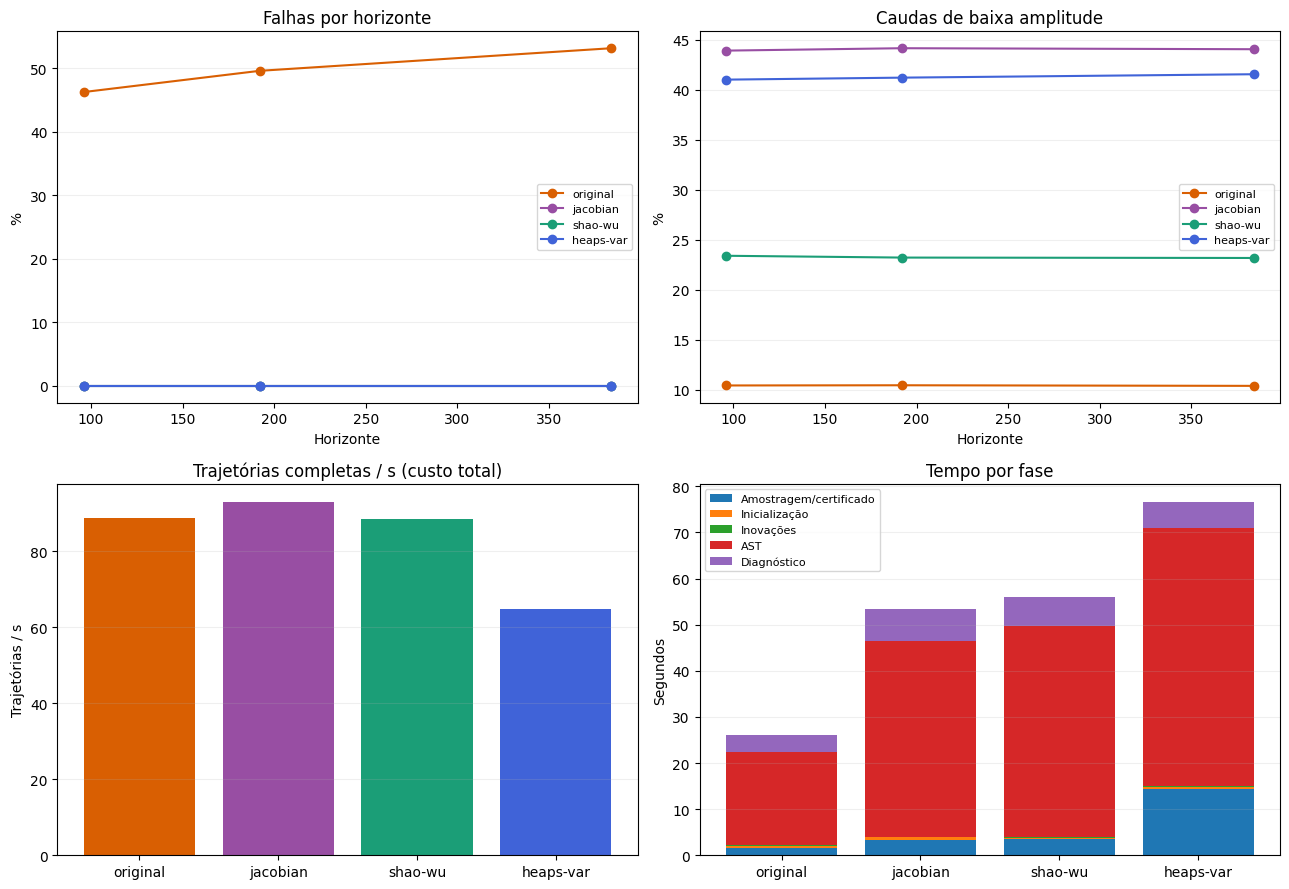

In [5]:
colors = {"original": "#d95f02", "jacobian": "#984ea3", "shao-wu": "#1b9e77", "heaps-var": "#4063d8"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for method in METHOD_ORDER:
    s = summary[summary.method.eq(method)]
    axes[0, 0].plot(s.horizon, 100*s.explosion_rate, marker="o", label=method, color=colors[method])
    axes[0, 1].plot(s.horizon, 100*s.near_zero_rate, marker="o", label=method, color=colors[method])
axes[0, 0].set(title="Falhas por horizonte", xlabel="Horizonte", ylabel="%")
axes[0, 1].set(title="Caudas de baixa amplitude", xlabel="Horizonte", ylabel="%")
p = performance.set_index("method").loc[METHOD_ORDER]
axes[1, 0].bar(METHOD_ORDER, p.successful_full_trajectories_per_second, color=list(colors.values()))
axes[1, 0].set(title="Trajetórias completas / s (custo total)", ylabel="Trajetórias / s")
bottom = np.zeros(len(METHOD_ORDER))
for key, label in [("sampling_and_certificate_seconds", "Amostragem/certificado"),
                   ("initialization_seconds", "Inicialização"),
                   ("innovation_seconds", "Inovações"), ("ast_execution_seconds", "AST"),
                   ("diagnostic_seconds", "Diagnóstico")]:
    axes[1, 1].bar(METHOD_ORDER, p[key], bottom=bottom, label=label)
    bottom += p[key].to_numpy()
axes[1, 1].set(title="Tempo por fase", ylabel="Segundos")
for axis in axes.flat:
    axis.grid(alpha=.2, axis="y")
for axis in (axes[0, 0], axes[0, 1], axes[1, 1]):
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()


**O que foi feito.** Os gráficos mostram resultados por horizonte, velocidade total e custos por fase, com histórico inicial sorteado diretamente.

## 6. Caudas quase constantes, persistência e redução de amplitude

### 6.1. Protocolo operacional implementado

Para cada prefixo completo e sem explosão:

1. Separe a **janela inicial** (primeiros 24 valores gerados), a **cauda** (últimos 24) e as **duas janelas terminais consecutivas** (últimos 48). Elas usam somente os valores disponíveis até o horizonte avaliado.
2. Em cada canal, calcule a média da janela e o maior desvio absoluto em torno dela. O maior desses desvios entre os canais é $V_h^{\mathrm{tail}}$ do relatório:
   $$V_h^{\mathrm{tail}}=\max_k\max_{h-24<v\le h}|x_{k,v}-\bar x^{\mathrm{tail}}_{k,h}|.$$
3. Marque **cauda quase constante** quando $V_h^{\mathrm{tail}}\le\delta_{\mathrm{flat}}$. A referência é $\delta_{\mathrm{flat}}=3\sigma_\varepsilon=0.15$, com $\sigma_\varepsilon=0.05$.
4. Exija **persistência**: cada uma das duas janelas terminais precisa passar, e os 48 valores juntos devem caber na mesma tolerância ao redor de sua média. O teste conjunto detecta mudanças entre dois patamares individualmente constantes.
5. Marque **redução de variação** quando há algum canal inicialmente acima da tolerância e todos esses canais terminam com variação persistente de no máximo metade da inicial. Exija também quase constância persistente de todos os canais. Registre separadamente os casos quietos tanto no início quanto no fim; o comportamento intermediário pode variar.
6. Marque **redução de amplitude para perto de zero** quando os últimos 48 valores de todos os canais ficam em $[-0.15,0.15]$, há algum canal inicialmente fora dessa faixa e cada canal assim identificado reduz seu máximo absoluto em pelo menos 50%. Essa medida usa amplitude em torno de zero; a anterior usa variação em torno da média.

**Patamar afastado de zero** significa quase constância persistente com média final de algum canal fora de $[-0.15,0.15]$. Os rótulos descrevem observações finitas e podem se sobrepor. A redução de amplitude é evidência entre janelas, enquanto convergência assintótica requer uma análise própria.

As tolerâncias e o fator 0.5 são escolhas operacionais configuráveis do projeto, fixadas antes desta execução. A seção 6.4 compara $1\sigma$, $2\sigma$ e $3\sigma$. Prefixos explosivos ficam **inelegíveis** para a análise de caudas e permanecem no denominador de 5.000 tentativas. Também mostramos a porcentagem condicionada aos prefixos elegíveis, identificada como tal.

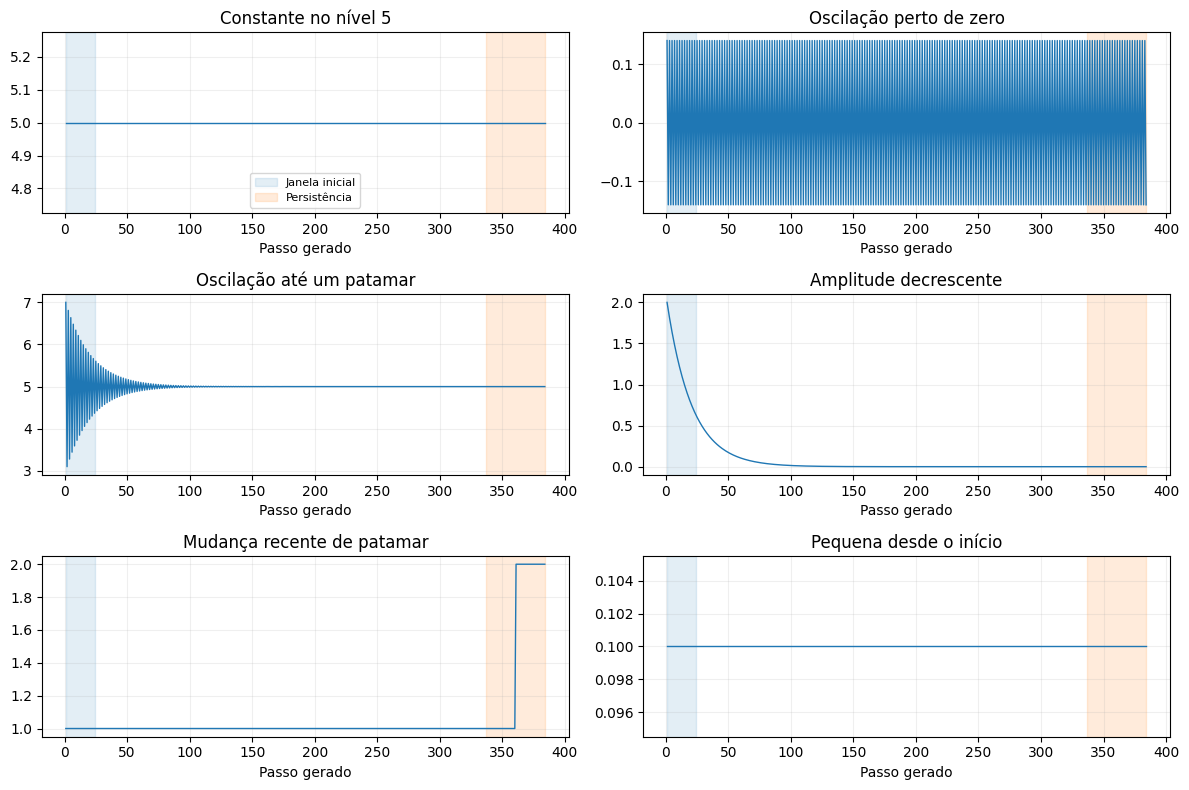

,example,flat_tail,persistent_flat_tail,quiet_initial_and_tail,flattening,flat_nonzero,persistent_near_zero,amplitude_decline_near_zero
0,Constante no nível 5,True,True,True,False,True,False,False
1,Oscilação perto de zero,True,True,True,False,False,True,False
2,Oscilação até um patamar,True,True,False,True,True,False,False
3,Amplitude decrescente,True,True,False,True,False,True,True
4,Mudança recente de patamar,True,False,False,False,False,False,False
5,Pequena desde o início,True,True,True,False,False,True,False


In [6]:
# Exemplos didáticos determinísticos, separados dos 20.000 casos do benchmark.
t = np.arange(max(HORIZONS))
illustrations = {
    "Constante no nível 5": np.full(t.size, 5.),
    "Oscilação perto de zero": .14 * (-1.)**t,
    "Oscilação até um patamar": 5. + 2. * np.exp(-t / 20.) * (-1.)**t,
    "Amplitude decrescente": 2. * np.exp(-t / 20.),
    "Mudança recente de patamar": np.where(t < t.size - 24, 1., 2.),
    "Pequena desde o início": np.full(t.size, .1),
}
demo_rows = []
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for axis, (name, values) in zip(axes.flat, illustrations.items()):
    stats = measure_tail_prefixes(values, DIAGNOSTIC_CONFIG, TAIL_CONFIG)[-1]
    labels = classify_tail_windows(stats, TAIL_CONFIG, near_zero_radius=DIAGNOSTIC_CONFIG.near_zero_radius)
    demo_rows.append({"example": name, **labels})
    axis.plot(t + 1, values, linewidth=1)
    axis.axvspan(1, 24, color="tab:blue", alpha=.12, label="Janela inicial")
    axis.axvspan(t.size - 47, t.size, color="tab:orange", alpha=.15, label="Persistência")
    axis.set(title=name, xlabel="Passo gerado")
    axis.grid(alpha=.2)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame(demo_rows))


**O que foi feito.** Os exemplos isolam os conceitos. A oscilação de amplitude 0.14 cabe na tolerância de 0.15; a análise com tolerância menor mostrará a dependência desse rótulo. A mudança recente de patamar passa na última janela e falha na persistência conjunta.

### 6.2. Resultados por horizonte

Cada contagem tem 5.000 tentativas no denominador. As colunas de elegibilidade permitem identificar quantas trajetórias completaram cada horizonte. Os intervalos de Wilson ficam no registro completo.

,method,horizon,N,eligible,flat_tail,persistent_flat_tail,quiet_initial_and_tail,flattening,flat_nonzero,persistent_near_zero,amplitude_decline_near_zero
0,original,96,5000,2687,969,791,196,459,268,431,238
1,original,192,5000,2520,962,819,191,480,270,451,259
2,original,384,5000,2342,958,785,192,459,251,438,247
3,jacobian,96,5000,5000,4996,4987,2920,1272,1883,2120,244
4,jacobian,192,5000,5000,4995,4988,2920,1268,1888,2131,233
5,jacobian,384,5000,5000,4994,4984,2921,1271,1877,2135,245
6,shao-wu,96,5000,5000,4426,3631,656,2389,2261,965,302
7,shao-wu,192,5000,5000,4441,3835,671,2547,2436,959,284
8,shao-wu,384,5000,5000,4422,3763,657,2498,2379,956,286
9,heaps-var,96,5000,5000,2340,1478,1150,9,2,1370,14


,flat_tail (%),persistent_flat_tail (%),quiet_initial_and_tail (%),flattening (%),flat_nonzero (%),persistent_near_zero (%),amplitude_decline_near_zero (%)
method,,,,,,,
original,19.16,15.70,3.84,9.18,5.02,8.76,4.94
jacobian,99.88,99.68,58.42,25.42,37.54,42.70,4.90
shao-wu,88.44,75.26,13.14,49.96,47.58,19.12,5.72
heaps-var,46.16,29.36,22.98,0.22,0.02,27.58,0.30


,flat_tail (% elegíveis),persistent_flat_tail (% elegíveis),quiet_initial_and_tail (% elegíveis),flattening (% elegíveis),flat_nonzero (% elegíveis),persistent_near_zero (% elegíveis),amplitude_decline_near_zero (% elegíveis)
method,,,,,,,
original,40.91,33.52,8.20,19.60,10.72,18.70,10.55
jacobian,99.88,99.68,58.42,25.42,37.54,42.70,4.90
shao-wu,88.44,75.26,13.14,49.96,47.58,19.12,5.72
heaps-var,46.16,29.36,22.98,0.22,0.02,27.58,0.30


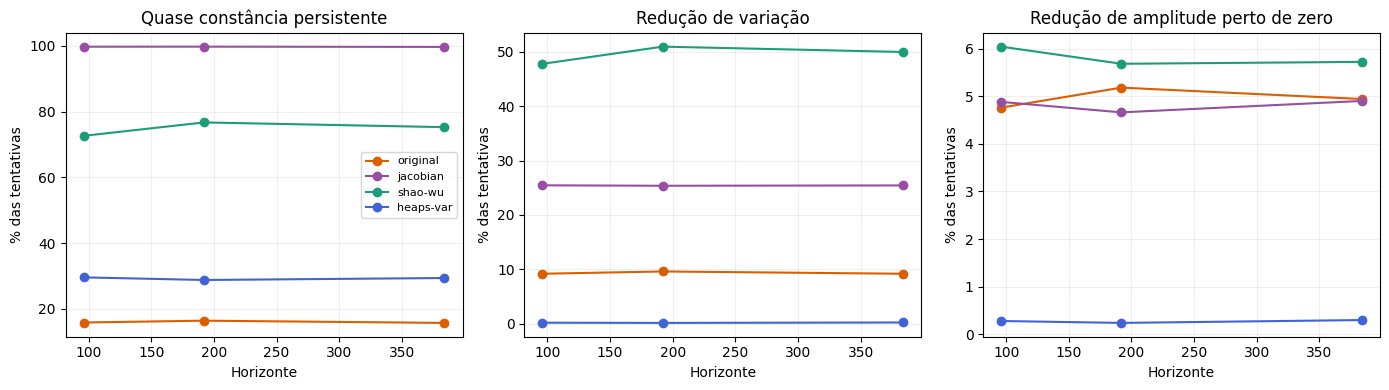

In [7]:
count_columns = ["method", "horizon", "N", "eligible"] + list(TAIL_LABELS)
display(tail_summary[count_columns])
horizon_results = tail_summary[tail_summary.horizon.eq(max(HORIZONS))].set_index("method").loc[METHOD_ORDER]
percentages = 100 * horizon_results[[label + "_rate" for label in TAIL_LABELS]]
display(percentages.round(2).rename(columns=lambda s: s.replace("_rate", " (%)")))
conditional = 100 * horizon_results[[label + "_among_eligible" for label in TAIL_LABELS]]
display(conditional.round(2).rename(columns=lambda s: s.replace("_among_eligible", " (% elegíveis)")))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for method in METHOD_ORDER:
    selected = tail_summary[tail_summary.method.eq(method)]
    for axis, label, title in zip(
        axes, ["persistent_flat_tail", "flattening", "amplitude_decline_near_zero"],
        ["Quase constância persistente", "Redução de variação", "Redução de amplitude perto de zero"],
    ):
        axis.plot(selected.horizon, 100 * selected[label + "_rate"], marker="o",
                  label=method, color=colors[method])
        axis.set(title=title, xlabel="Horizonte", ylabel="% das tentativas")
        axis.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


**O que foi feito.** Calculamos contagens e taxas para as mesmas trajetórias, com denominadores total e elegível explicitamente separados. As curvas mostram como cada rótulo muda com o horizonte; elas compartilham as trajetórias e, portanto, têm dependência entre horizontes.

### 6.3. Auditoria das médias e variações

As médias por canal e os desvios ficam nas linhas individuais de `outcomes`, juntamente com o índice do mecanismo. A tabela abaixo mostra exemplos de cada rótulo encontrado.

In [8]:
representatives = []
for method in METHOD_ORDER:
    candidates = outcomes[outcomes.method.eq(method) & outcomes.horizon.eq(max(HORIZONS))]
    for label in ["quiet_initial_and_tail", "flattening", "flat_nonzero", "amplitude_decline_near_zero"]:
        rows = candidates[candidates[label]]
        if len(rows):
            row = rows.iloc[0]
            representatives.append({
                "method": method, "label": label, "sample_index": int(row.sample_index),
                "initial_mean": row.initial_mean, "tail_mean": row.tail_mean,
                "initial_variation": row.initial_variation,
                "tail_variation": row.tail_variation,
                "persistent_variation": row.persistent_variation,
                "flat_tolerance": TAIL_CONFIG.flat_tolerance, "innovation_std": INNOVATION_STD,
            })
representative_table = pd.DataFrame(representatives)
display(representative_table)


,method,label,sample_index,initial_mean,tail_mean,initial_variation,tail_variation,persistent_variation,flat_tolerance,innovation_std
0,original,quiet_initial_and_tail,11,"(-0.6800625936081617,)","(-0.7041448822716777,)","(0.12046948672057589,)","(0.10134597879566276,)","(0.11688609326792099,)",0.15,0.05
1,original,flattening,3,"(-0.021236634175061792,)","(-0.002540254008987159,)","(0.3763536808162134,)","(0.11777216195817067,)","(0.12061847751168008,)",0.15,0.05
2,original,flat_nonzero,11,"(-0.6800625936081617,)","(-0.7041448822716777,)","(0.12046948672057589,)","(0.10134597879566276,)","(0.11688609326792099,)",0.15,0.05
3,original,amplitude_decline_near_zero,3,"(-0.021236634175061792,)","(-0.002540254008987159,)","(0.3763536808162134,)","(0.11777216195817067,)","(0.12061847751168008,)",0.15,0.05
4,jacobian,quiet_initial_and_tail,0,"(-0.8561922559625724,)","(-0.8609579427333142,)","(0.08410136437145477,)","(0.08460336853581618,)","(0.0877967945327146,)",0.15,0.05
5,jacobian,flattening,4,"(0.0414424475580269,)","(-0.0008393095619623295,)","(0.19226341083817128,)","(0.0762555082554756,)","(0.09231934340673006,)",0.15,0.05
6,jacobian,flat_nonzero,0,"(-0.8561922559625724,)","(-0.8609579427333142,)","(0.08410136437145477,)","(0.08460336853581618,)","(0.0877967945327146,)",0.15,0.05
7,jacobian,amplitude_decline_near_zero,35,"(-0.030393178258406484,)","(-0.00696250172455597,)","(0.22244993662749613,)","(0.07833358218485988,)","(0.12518075954186328,)",0.15,0.05
8,shao-wu,quiet_initial_and_tail,2,"(0.042435006406356446,)","(0.02059102682990725,)","(0.14546060907930655,)","(0.09334242792362511,)","(0.10292322043049479,)",0.15,0.05
9,shao-wu,flattening,0,"(-1.4788182812619102,)","(-1.7292947626296378,)","(0.9458725287348839,)","(0.11743457320360684,)","(0.13113888616211677,)",0.15,0.05


**O que foi feito.** Exibimos valores que permitem auditar a classificação sem confundir nível médio, variação em torno da média e amplitude em torno de zero. Para cada rótulo, selecionamos o primeiro índice que o satisfaz; a seleção tem finalidade ilustrativa.

### 6.4. Sensibilidade à tolerância e leitura dos resultados

As mesmas estatísticas das mesmas trajetórias são reclassificadas com tolerâncias 0.05, 0.10 e 0.15. Mantemos a janela de 24 passos, a persistência de 48 passos e a redução mínima de 50%. O custo dessa reclassificação está incluído no tempo de diagnóstico.

,method,flat_tolerance,N,eligible,flat_tail,persistent_flat_tail,quiet_initial_and_tail,flattening,flat_nonzero
6,original,0.05,5000,2342,0,0,0,0,0
7,original,0.10,5000,2342,291,72,5,36,21
8,original,0.15,5000,2342,958,785,192,459,251
15,jacobian,0.05,5000,5000,0,0,0,0,0
16,jacobian,0.10,5000,5000,4145,3399,969,592,1080
17,jacobian,0.15,5000,5000,4994,4984,2921,1271,1877
24,shao-wu,0.05,5000,5000,1,0,0,0,0
25,shao-wu,0.10,5000,5000,1443,300,17,201,189
26,shao-wu,0.15,5000,5000,4422,3763,657,2498,2379
33,heaps-var,0.05,5000,5000,0,0,0,0,0


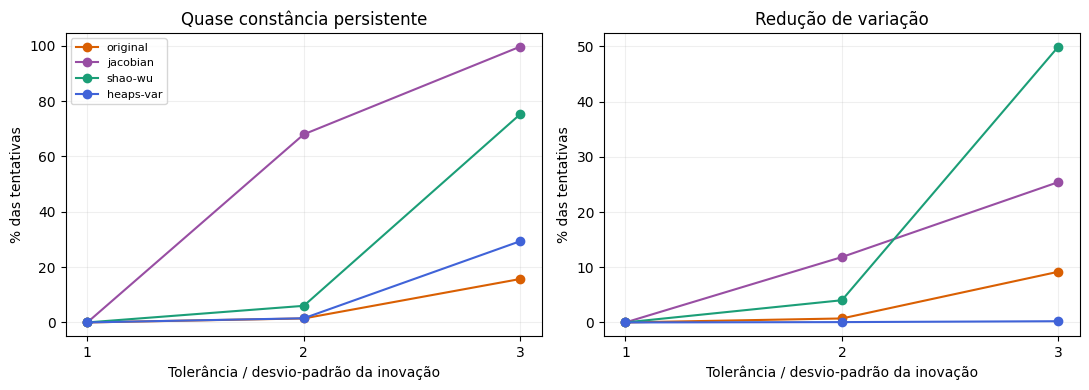

Resultados em h=384, com tolerância 0.15:

- **original:** 785/5000 caudas persistentemente pequenas em torno da própria média; 459/5000 com redução de variação; 192/5000 quietas nas duas extremidades; 251/5000 em patamar afastado de zero; 247/5000 com redução de amplitude para perto de zero.
- **jacobian:** 4984/5000 caudas persistentemente pequenas em torno da própria média; 1271/5000 com redução de variação; 2921/5000 quietas nas duas extremidades; 1877/5000 em patamar afastado de zero; 245/5000 com redução de amplitude para perto de zero.
- **shao-wu:** 3763/5000 caudas persistentemente pequenas em torno da própria média; 2498/5000 com redução de variação; 657/5000 quietas nas duas extremidades; 2379/5000 em patamar afastado de zero; 286/5000 com redução de amplitude para perto de zero.
- **heaps-var:** 1468/5000 caudas persistentemente pequenas em torno da própria média; 11/5000 com redução de variação; 1149/5000 quietas nas duas extremidades; 1/5000 em patamar afastado de zero; 15/5000 com redução de amplitude para perto de zero.

In [9]:
sensitivity_final = sensitivity_summary[sensitivity_summary.horizon.eq(max(HORIZONS))]
display(sensitivity_final[["method", "flat_tolerance", "N", "eligible", "flat_tail",
                           "persistent_flat_tail", "quiet_initial_and_tail", "flattening", "flat_nonzero"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method in METHOD_ORDER:
    selected = sensitivity_final[sensitivity_final.method.eq(method)]
    for axis, label, title in zip(axes, ["persistent_flat_tail", "flattening"],
                                  ["Quase constância persistente", "Redução de variação"]):
        axis.plot(selected.flat_tolerance / INNOVATION_STD, 100 * selected[label + "_rate"],
                  marker="o", color=colors[method], label=method)
        axis.set(title=title, xlabel="Tolerância / desvio-padrão da inovação",
                 ylabel="% das tentativas", xticks=[1, 2, 3])
        axis.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
statements = []
for method, row in horizon_results.iterrows():
    statements.append(
        f"- **{method}:** {int(row.persistent_flat_tail)}/5000 caudas persistentemente pequenas "
        f"em torno da própria média; {int(row.flattening)}/5000 com redução de variação; "
        f"{int(row.quiet_initial_and_tail)}/5000 quietas nas duas extremidades; "
        f"{int(row.flat_nonzero)}/5000 em patamar afastado de zero; "
        f"{int(row.amplitude_decline_near_zero)}/5000 com redução de amplitude para perto de zero."
    )
display(Markdown("Resultados em h=384, com tolerância 0.15:\n\n" + "\n".join(statements)))


**O que foi feito.** Avaliamos a dependência das conclusões em relação à tolerância sem regenerar séries. Inovações persistentes sustentam variação mesmo em mecanismos estáveis. Quase constância dentro de uma faixa, quietude nos extremos e redução desde o início respondem a perguntas diferentes.

## Interpretação

Jacobiana certifica uma caixa invariante sob ruído limitado; Shao–Wu usa limites globais e inicialização aproximada com erro declarado; Heaps constrói VARs com histórico estacionário conjunto. Gaussianas podem ultrapassar limiares finitos mesmo em processos estacionários; por isso cruzamentos finitos e valores não finitos também são registrados.

Sementes locais por índice isolam a geração do RNG global do programa do usuário e da ordem dos jobs. Os testes correspondentes ficam em tests/unit/.

Os novos diagnósticos preservam o sinal e o nível de cada canal. Quase constância persistente, quietude inicial/final e redução de variação são medidas separadas. Os resultados dependem da tolerância e da duração observada. A geração mantém os fluxos aleatórios da execução anterior; a medição adicional altera os custos de diagnóstico.

## Registro completo do experimento

In [10]:
def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=PROJECT_ROOT,
                                       text=True, stderr=subprocess.DEVNULL).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None

source_paths = [
    "src/tsfmxai/representations/expression.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/trajectory.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/evaluation/stability.py",
    "src/tsfmxai/evaluation/generator_tradeoff.py",
    "src/tsfmxai/evaluation/tail_behavior.py",
    "src/tsfmxai/evaluation/__init__.py",
]
record = {
    "experiment_id": EXPERIMENT_ID, "status": "executed",
    "research_question": RESEARCH_QUESTION,
    "hypothesis": HYPOTHESIS,
    "configuration": configuration,
    "seed_policy": {
        "mechanisms": "derive_sample_seed(ROOT_SEED, index)",
        "benchmark_initialization_and_future_noise": "SeedSequence([ROOT_SEED, index, 991]).spawn(2)",
        "multiple_trajectories": "SeedSequence([root_seed, trajectory_index]).spawn(2)",
        "external_global_rng": False,
        "note": "Per-index local streams isolate generation from user RNG state and worker scheduling.",
    },
    "provenance": {
        "git_head": git_output("rev-parse", "HEAD"), "dirty_worktree": bool(git_output("status", "--porcelain")),
        "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest()
                          for name in source_paths},
        "python": sys.version, "platform": platform.platform(),
        "packages": {name: importlib.metadata.version(name)
                     for name in ("numpy", "pandas", "matplotlib", "joblib", "threadpoolctl")},
        "blas": threadpool_info(), "execution": "serial wall-clock; BLAS threads=1",
        "references": {"Shao-Wu": "https://arxiv.org/abs/math/0611029",
                       "Heaps": "https://arxiv.org/abs/2004.09455"},
    },
    "metrics": {"tails": json.loads(tail_summary.to_json(orient="records")),
                "tail_sensitivity": json.loads(sensitivity_summary.to_json(orient="records")),
                "tail_examples": json.loads(representative_table.to_json(orient="records")),
                "stability": json.loads(summary.to_json(orient="records")),
                "performance": json.loads(performance.to_json(orient="records")),
                "additional_checks": additional_checks},
    "scientific_summary": [
        f"{r.method}: h={r.horizon}, {r.explosions}/{r.N} threshold failures; "
        f"{r.near_zero}/{r.N} low-amplitude tails."
        for r in summary[summary.horizon.eq(max(HORIZONS))].itertuples()
    ],
    "tail_scientific_summary": statements,
    "limitations": [
        "Flatness uses signed per-channel deviations, delta=3 sigma; sensitivity uses 1,2,3 sigma.",
        "Persistence requires two terminal windows and their pooled 48-value interval to satisfy the same band.",
        "Initial and terminal windows are disjoint; quiet endpoints leave intervening variation unrestricted.",
        "Decline uses a configurable factor 0.5 on every initially active channel; labels can overlap.",
        "Finite-window decline is distinct from asymptotic convergence; failed prefixes are ineligible.",
        "All primary rates use all attempts; conditional eligible-only rates are recorded separately.",
        "Timing includes the extended diagnostics and all three sensitivity tolerances.",
        "near_zero means all final 24 values within +/-0.15, a finite-window low-amplitude label.",
        "Gaussian stationary samples may cross a finite threshold; threshold crossing and nonfinite outputs are recorded separately.",
        "One independent mechanism/realization per outcome denominator; Wilson intervals are over these samples.",
        "Families and native initialization/noise laws differ; matched variance does not make noise distributions identical.",
        "Shao-Wu starts from a direct uniform history and may have a finite-horizon transient; Heaps uses a joint invariant Gaussian history.",
        "Single-run timings include failed attempts; they are hardware-dependent, without timing confidence intervals.",
        "The mathematical mappings are published; random AST construction and explanation-ready storage are project adaptations.",
    ],
    "reproduction_command": (
        ".\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        + NOTEBOOK_PATH + " --ExecutePreprocessor.timeout=3600"
    ),
}
print(json.dumps(record, indent=2, ensure_ascii=False))


{
  "experiment_id": "abstract_syntax_tree_006_four_current_methods_tail_diagnostics_v2",
  "status": "executed",
  "research_question": "Qual o trade-off entre falhas operacionais, baixa amplitude e custo dos quatro geradores?",
  "hypothesis": "Certificados reduzem falhas nas famílias admitidas, com custo de construção e inicialização.",
  "configuration": {
    "root_seed": 20261001,
    "count_per_method": 5000,
    "num_series": 1,
    "diagnostics": {
      "horizons": [
        96,
        192,
        384
      ],
      "explosion_limit": 100.0,
      "near_zero_radius": 0.15000000000000002,
      "near_zero_tail_steps": 24
    },
    "original": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnit

**O que foi feito.** O registro reúne configuração, sementes, hashes de fontes, métricas, limitações e reprodução no próprio notebook executado.